## Part 2: Hunga Tonga Analysis

In [54]:
#importing needed libraries 
import numpy as np
import matplotlib.pyplot as plt 
import matplotlib.image as mpimg
import rasterio
import os
from matplotlib.colors import rgb_to_hsv
import datetime as dt

### 1. Setting Up

In [16]:
# folder paths 
folder = ('sentinel-data')
white_light = f'{folder}/White_light'
#creating folder for processed outputs - store for later 
out_path = 'sentinel-processed'
os.makedirs(out_path, exist_ok=True)

In [94]:
# extracting and sorting sentinel and google earth files 
#google earth images (verifying .jpg files due to .ipynb_checkpoints issue)
def get_google_files(path):
    files = [f for f in os.listdir(path) if f.endswith('.jpg')]
    return sorted(files)

#getting the sentinel-2 folders 
def get_sentinel_folders(path):
    folders = [f for f in os.listdir(path) if f.startswith("S2_")]
    return sorted(folders)

#extracting files from folders 
def get_sentinel_files(f, band, path='sentinel-data'):
    return f'{path}/{f}/Sentinel-2_L2A_{band}_Raw.tiff'

In [18]:
#getting files
google_files = get_google_files(white_light)
s2_folders = get_sentinel_folders(folder)
#printing to check completeness
print('google earth images:', google_files)
print('sentinel-2 folders:', s2_folders)
print('example band path:', get_sentinel_files(s2_folders[0], 'B04'))

google earth images: ['2014Feb.jpg', '2016May.jpg', '2020Nov.jpg', '2021Dec.jpg', '2022Jan.jpg', '2023Oct.jpg']
sentinel-2 folders: ['S2_2017-07-12', 'S2_2018-07-12', 'S2_2019-07-12']
example band path: sentinel-data/S2_2017-07-12/Sentinel-2_L2A_B04_Raw.tiff


### 2. Google Earth Images - loading images and scale bar 

In [ ]:
# how many metres does one pixel cover - > metres per pixel = distance/bar length in pixels

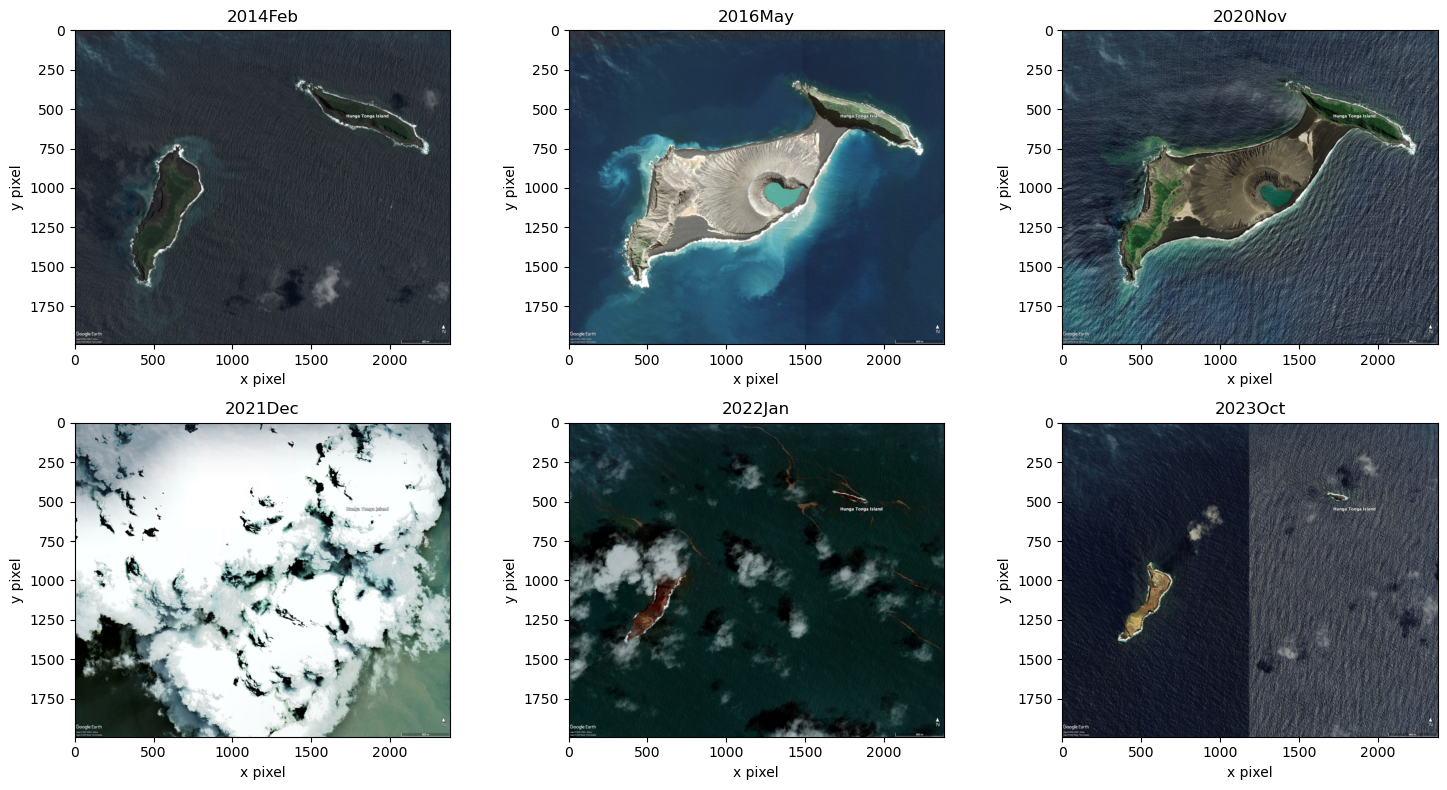

In [26]:
# loading and displaying all images 
#defeining function to load google image as rgb array 
def load_google(name):
    return mpimg.imread(f'{white_light}/{name}')

#plotting google earth images for inspection 
def plot_google(files):
    fig, axes = plt.subplots(2,3,figsize=(15,8))
    for name, ax in zip(files,axes.flatten() ):
        img = load_google(name) #loading image files
        ax.imshow(img)
        ax.set_title(name[:-4])
        #labelling axes
        ax.set_xlabel("x pixel") 
        ax.set_ylabel("y pixel")
    plt.tight_layout()
    plt.show()
    
plot_google(google_files)

###  The 2021Dec image is almost completely covered by cloud, so the islands are not visible and the land area cannot be measured. This image is excluded from the land area calculation in step 4.

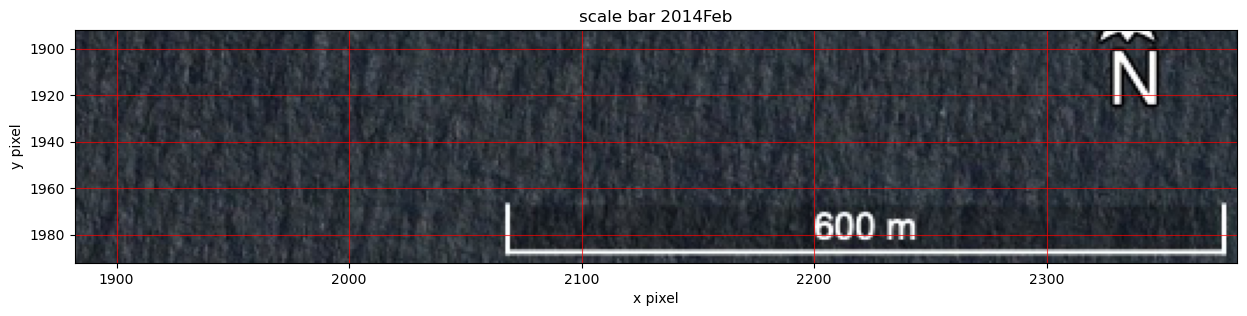

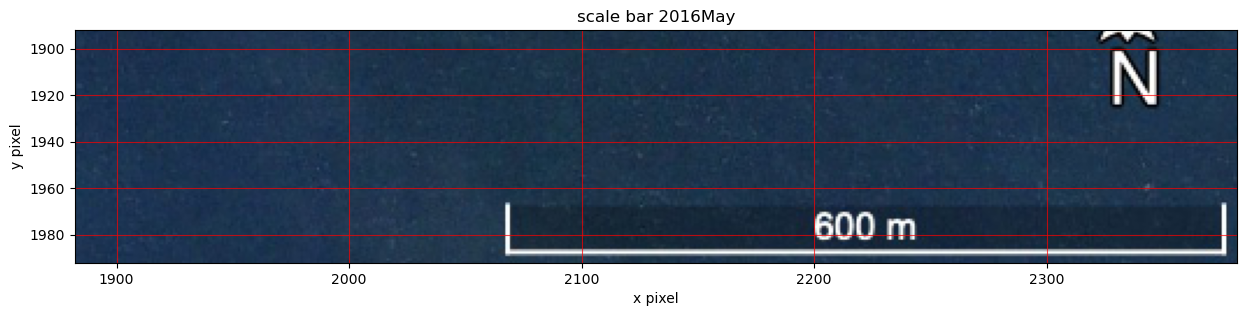

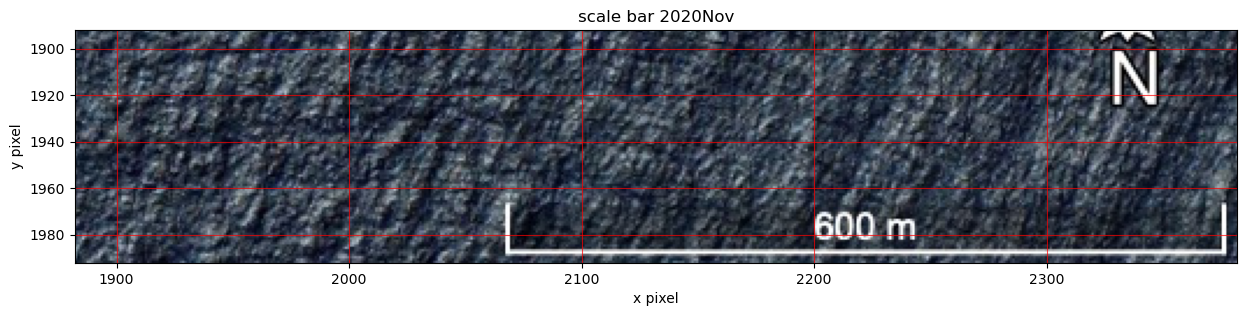

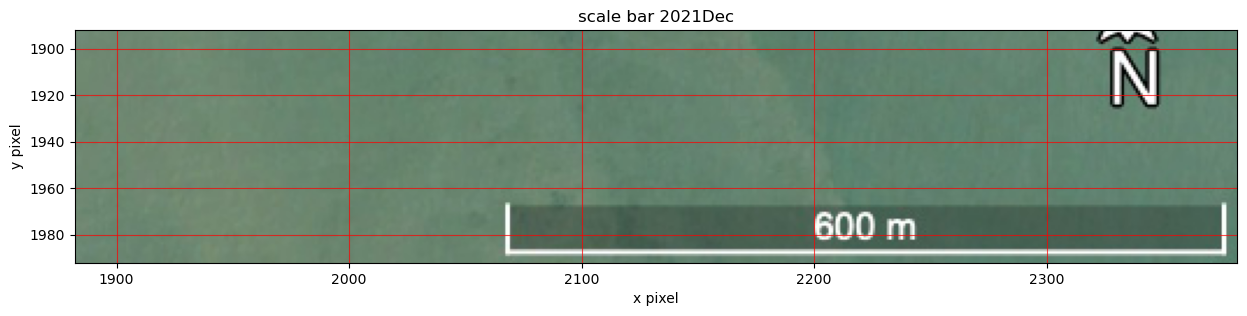

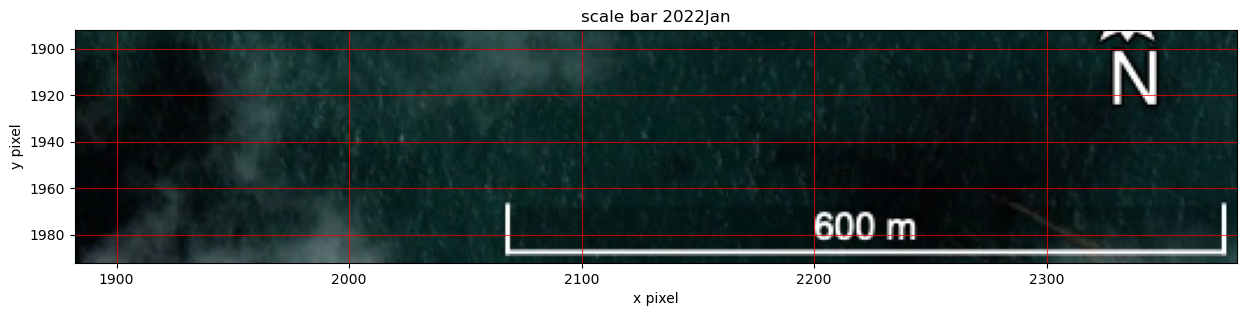

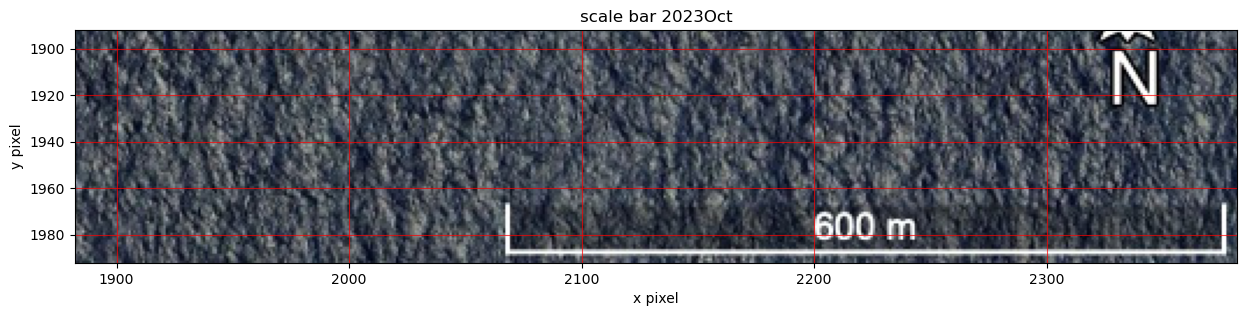

In [28]:
# zooming in on the scale bar 
# scale bar at bottom right of the mages 
def scale_bar(name, rows=100, cols=500):
    img = load_google(name)
    height, width, _ = img.shape
    fig, ax = plt.subplots(figsize=(15,8))
    #cutting out bottom corner - extent to keep actual pixels on labels
    ax.imshow(img[-rows:,-cols:], extent=[width - cols, width, height, height - rows])
    ax.set_title(f"scale bar {name[:-4]}") #name=date
    ax.set_xlabel("x pixel")
    ax.set_ylabel("y pixel")
    ax.grid(True, color='red', alpha=0.7) #red grid so we can see it
    plt.show()
for name in google_files:
    scale_bar(name)

In [31]:
#scale bar is a white line at y ≈ 1984 1990 right of x = 2050
def measure_bar(name, y_range=(1984, 1991), x_min=2050, white_lvl= 200):
    img = load_google(name)
    strip = img[y_range[0]:y_range[1], x_min:]
    # focusing on white pixels only - all colours bright
    white = np.all(strip > white_lvl, axis=2)
    #identifying where bar is 
    cols = np.where(white.any(axis=0))[0] + x_min 
    return cols.min() , cols.max()
    
bar_distance = 600 #label on scale bar 
m_per_pixel = {}
for name in google_files:
    start, end = measure_bar(name)
    bar_length = end-start+1
    m_per_pixel[name] = bar_distance / bar_length
    print(name, " bar from", start, "to", end, "bar length =", bar_length, "pixels,","metres per pixel =", round(m_per_pixel[name], 3))

2014Feb.jpg  bar from 2067 to 2376 bar length = 310 pixels, metres per pixel = 1.935
2016May.jpg  bar from 2067 to 2376 bar length = 310 pixels, metres per pixel = 1.935
2020Nov.jpg  bar from 2067 to 2376 bar length = 310 pixels, metres per pixel = 1.935
2021Dec.jpg  bar from 2067 to 2376 bar length = 310 pixels, metres per pixel = 1.935
2022Jan.jpg  bar from 2067 to 2376 bar length = 310 pixels, metres per pixel = 1.935
2023Oct.jpg  bar from 2067 to 2376 bar length = 310 pixels, metres per pixel = 1.935


In [32]:
# calculating pixel area 
pixel_area = {}
for name in google_files:
    pixel_area[name] = m_per_pixel[name]**2
    print(name,":pixel area = ", round(pixel_area[name], 3), "m^2")

2014Feb.jpg :pixel area =  3.746 m^2
2016May.jpg :pixel area =  3.746 m^2
2020Nov.jpg :pixel area =  3.746 m^2
2021Dec.jpg :pixel area =  3.746 m^2
2022Jan.jpg :pixel area =  3.746 m^2
2023Oct.jpg :pixel area =  3.746 m^2


### Each pixel covers 1.935 m × 1.935 m, giving a pixel area of ≈ 3.746 m². Land area = number of land pixels × pixel area.

### 3. Land Mask on Google Earch Images

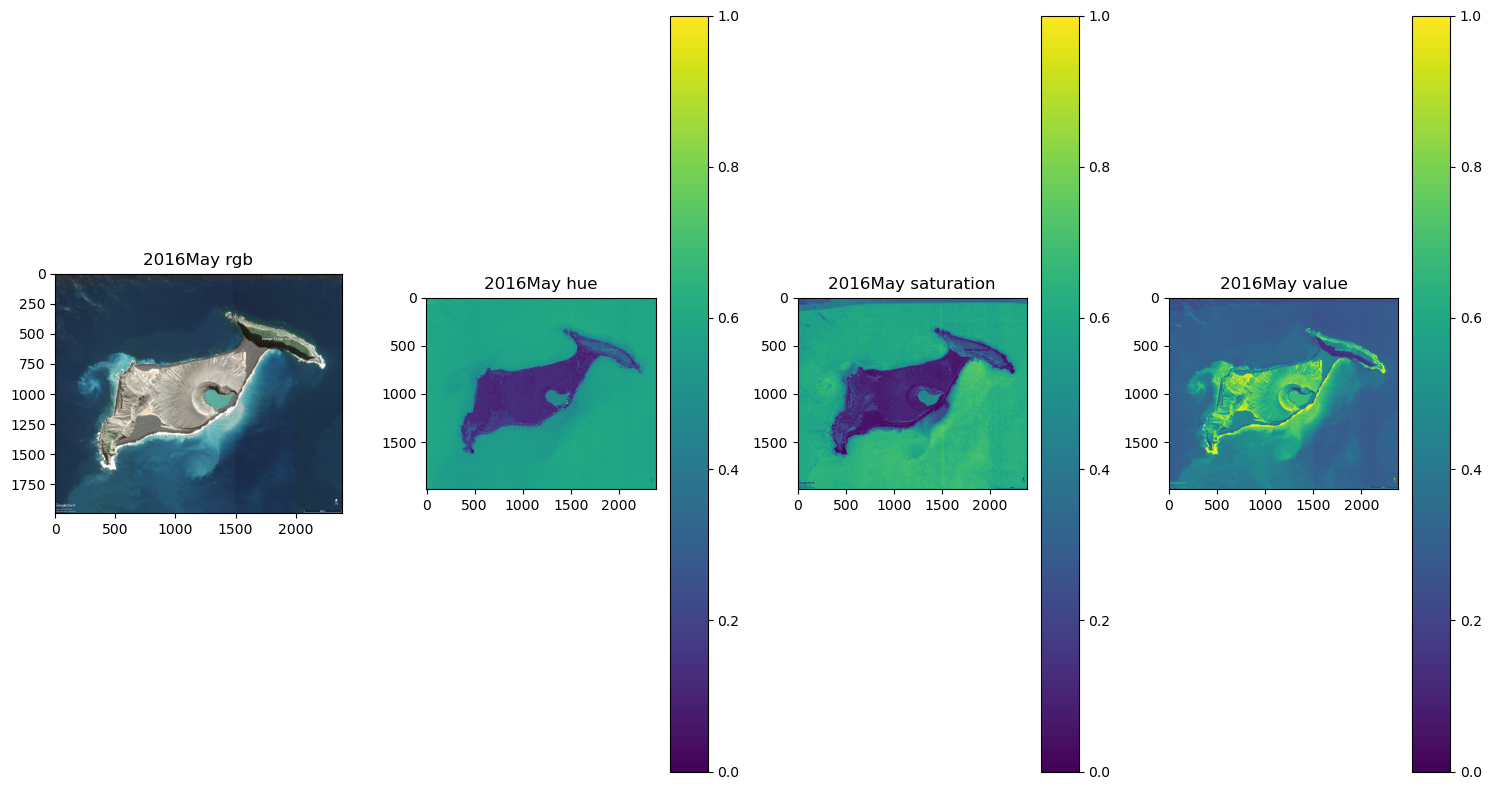

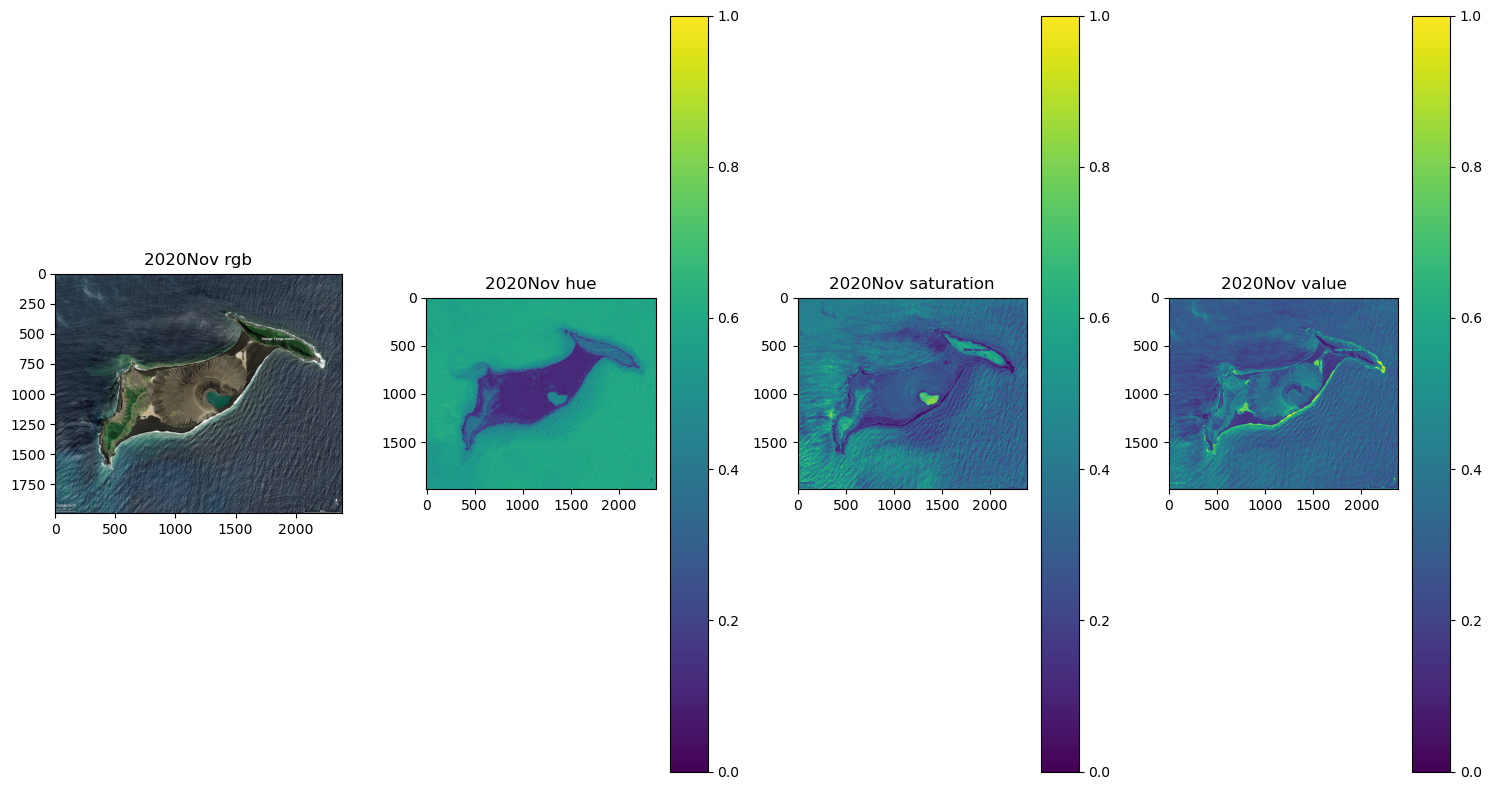

In [38]:
# converting rgb to hsv 
def hsv(img):
    return rgb_to_hsv(img/255)

#plotting rgb image next to its channels
def plot_hsv(name):
    img = load_google(name)
    hsv1 = hsv(img)
    fig, axes = plt.subplots(1, 4, figsize=(15, 8))
    axes[0].imshow(img)
    axes[0].set_title(f"{name[:-4]} rgb")
    for i, label in enumerate(['hue', 'saturation', 'value']):
        im = axes[i+1].imshow(hsv1[:, :, i], vmin=0, vmax=1)
        axes[i+1].set_title(f"{name[:-4]} {label}")
        plt.colorbar(im, ax=axes[i+1])
    plt.tight_layout()
    plt.show()

plot_hsv('2016May.jpg')
plot_hsv('2020Nov.jpg')

#### Comparing the three channels for 2016 May and 2020 Nov, hue gives the clearest separation between land and sea - sea is near uniform hue of around 0.6 and the island 0.1 giving a stark contrast - Hue is therefore used to build the land mask. 

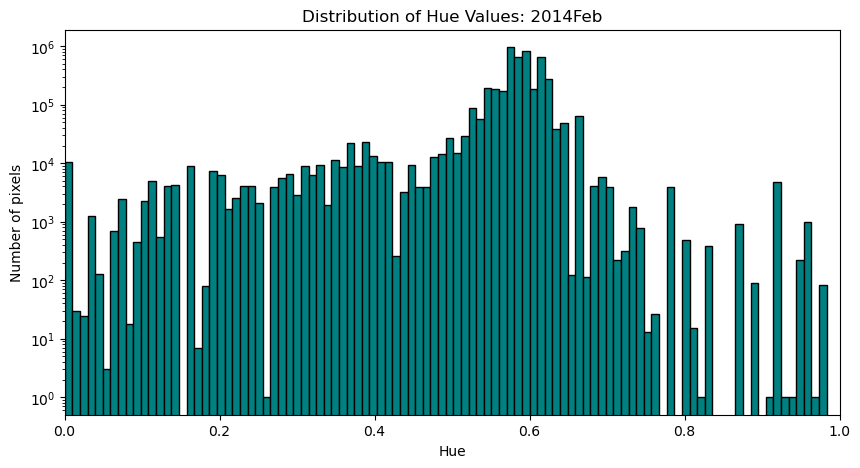

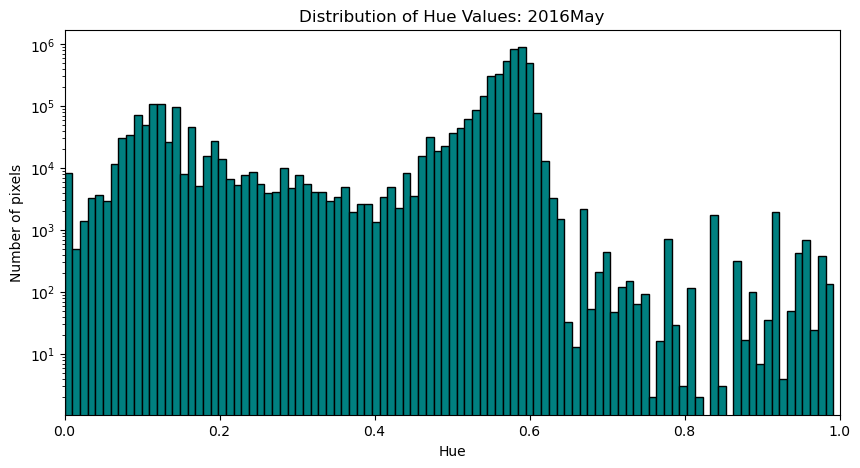

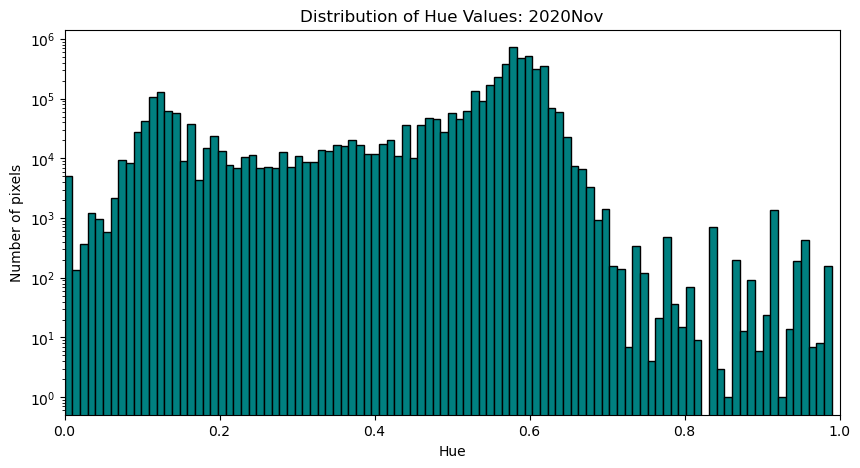

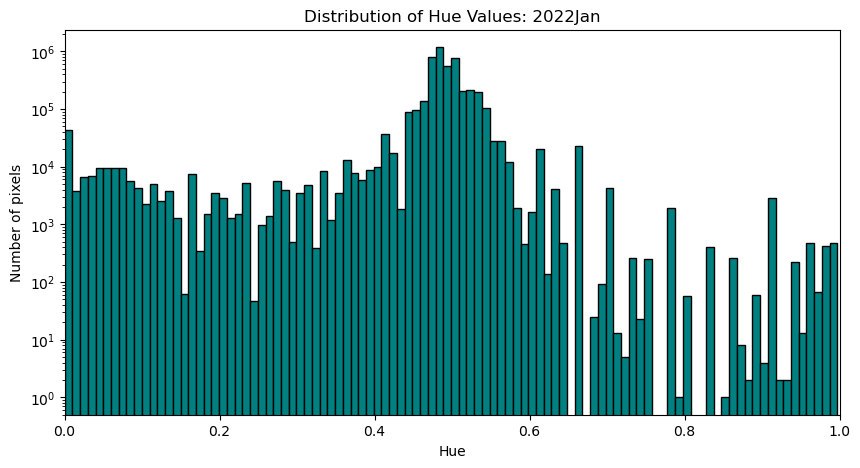

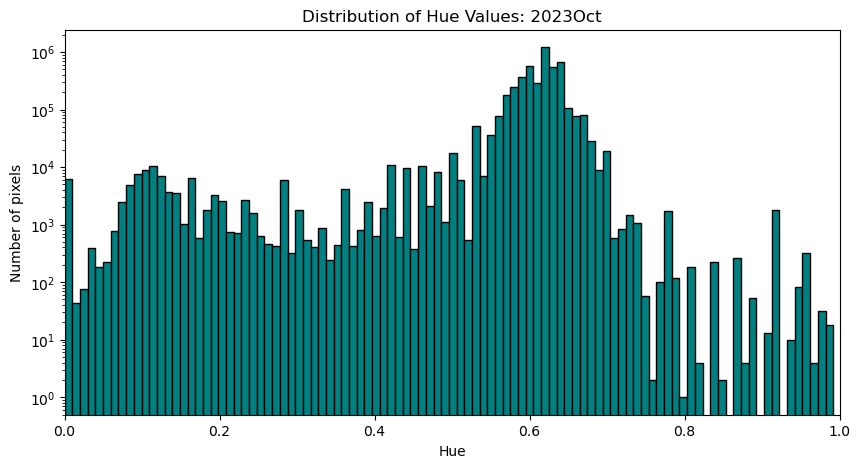

In [49]:
# choosing a hue threshold for land by histogram - plotting histogram
for name in google_files:
    #skip december 2021 - clouds only
    if name == '2021Dec.jpg':
        continue
    # Load the Google Earth images
    img = load_google(name)
    #Convert RGB to HSV
    hsv_image = hsv(img)
    #Extracting the hue channel
    hue = hsv_image[:, :, 0]
    #Plotting the distribution
    plt.figure(figsize=(10, 5))
    plt.hist(hue.ravel(), bins=100, color='teal', edgecolor='black')
    plt.xlabel('Hue')
    plt.ylabel('Number of pixels')
    plt.title(f'Distribution of Hue Values: {name[:-4]}')
    plt.xlim(0, 1)
    plt.yscale('log')
    plt.show()

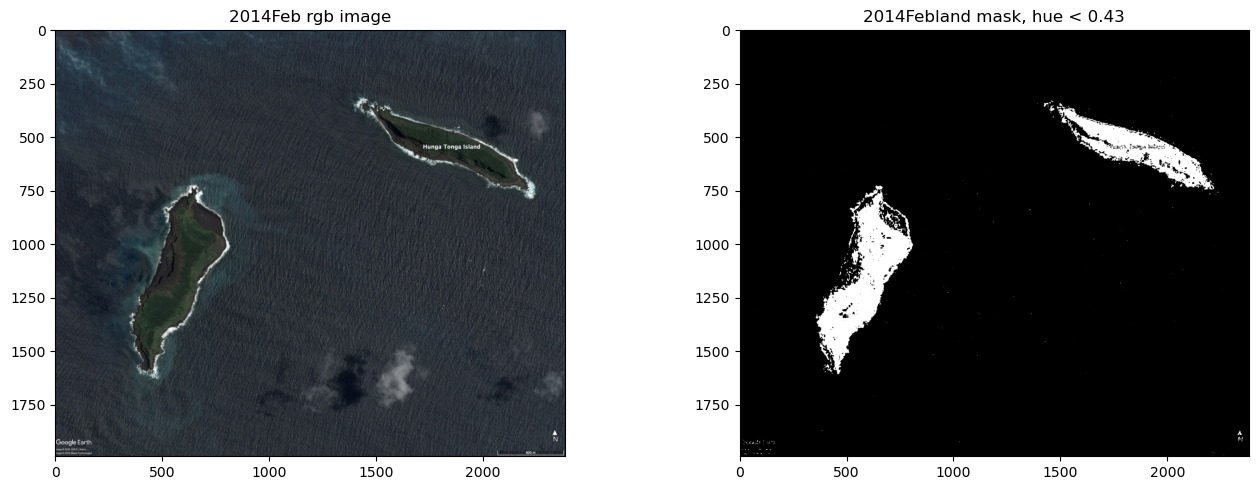

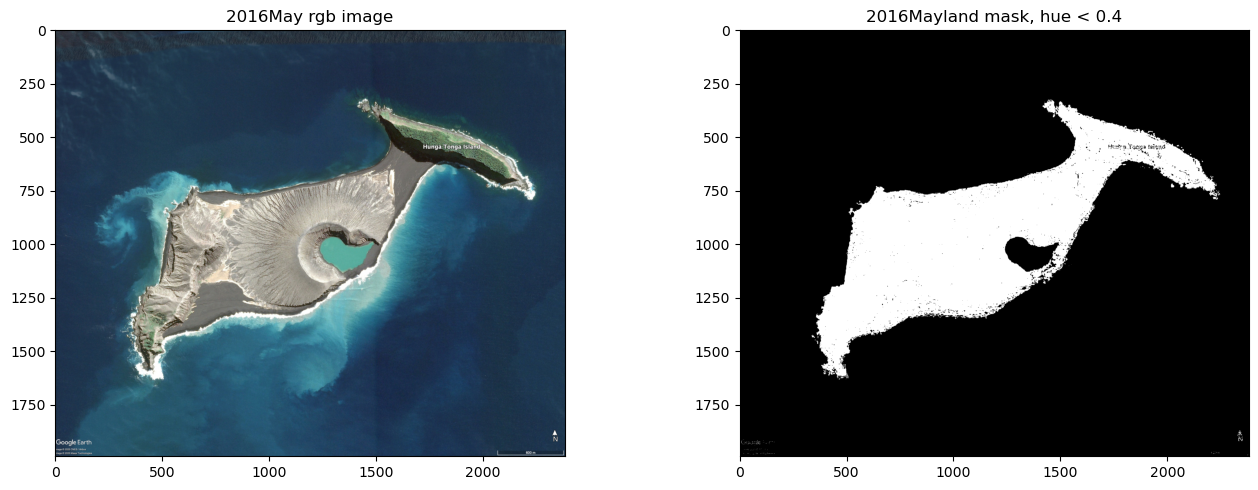

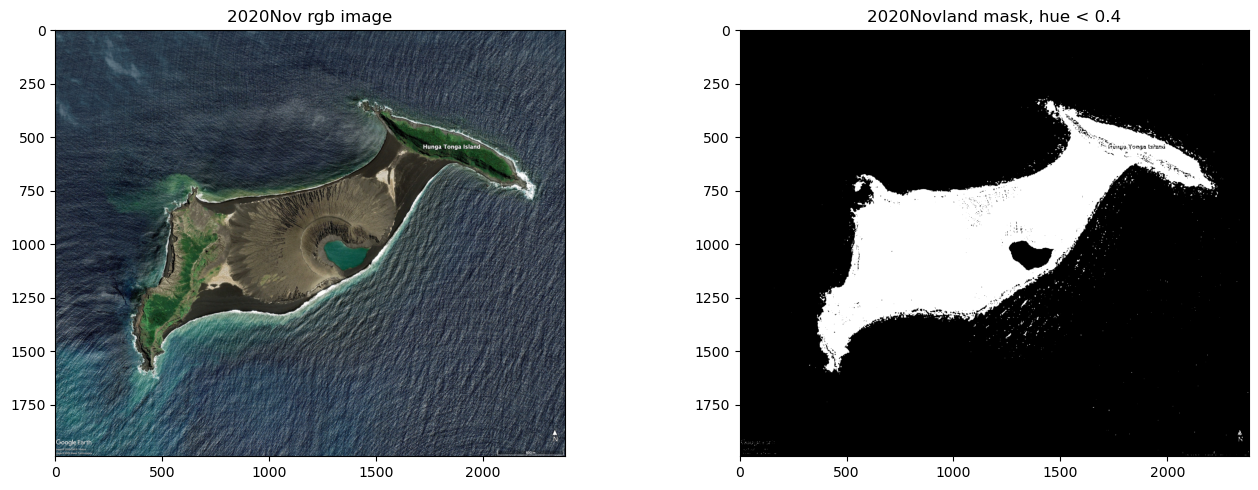

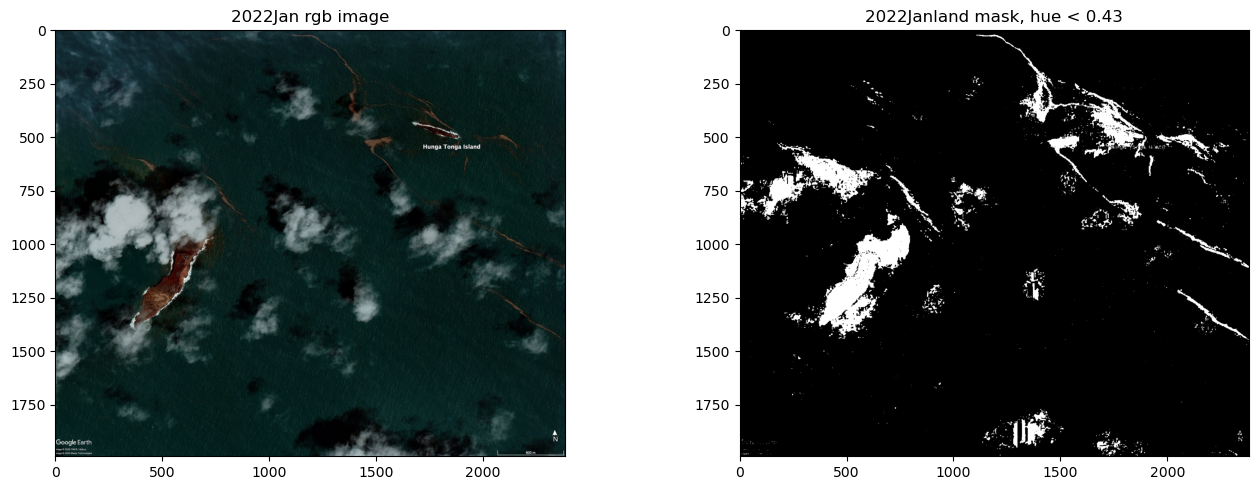

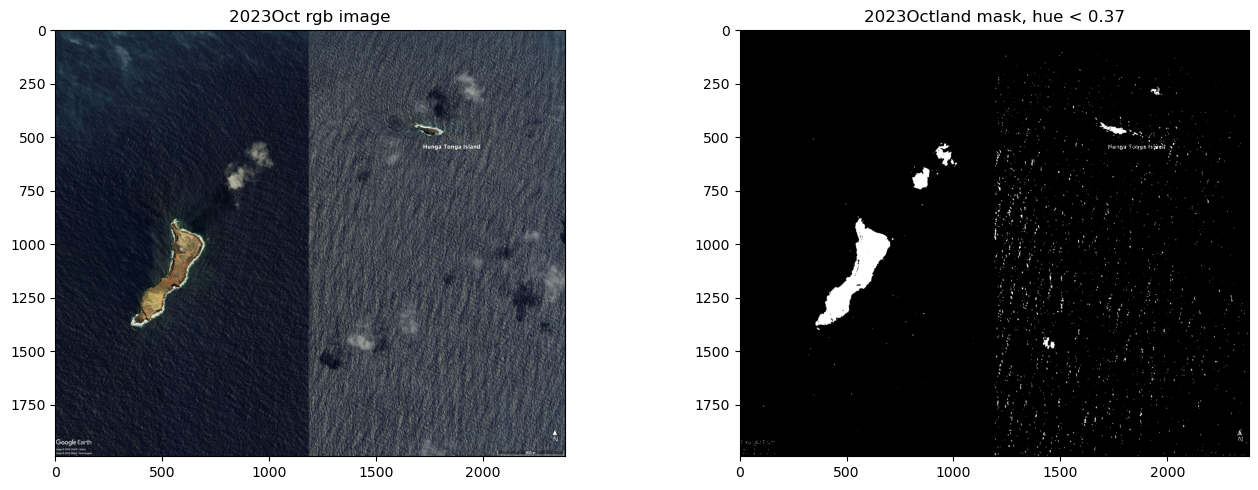

In [52]:
#checking visual thresholds against data 
hue_thresholds = {'2014Feb.jpg': 0.43,'2016May.jpg': 0.40,'2020Nov.jpg': 0.40,'2022Jan.jpg': 0.43,'2023Oct.jpg': 0.37}
#plotting rgb image side by side with hue threshold images
for name in hue_thresholds:
    img =load_google(name)
    hue =hsv(img)[:, :, 0]
    land =hue < hue_thresholds[name]
    fig, axes =plt.subplots(1, 2, figsize=(14, 5))
    axes[0].imshow(img)
    axes[0].set_title(f'{name[:-4]} rgb image')
    axes[1].imshow(land,cmap='gray')
    axes[1].set_title(f'{name[:-4]}land mask, hue < {hue_thresholds[name]}')
    plt.tight_layout()
    plt.show()

### The hue mask works well for 2014 Feb, 2016 May and 2020 Nov. In 2023 Oct, a few clouds and bright wave crests are included as land, slightly overestimating the area. In 2022 Jan, clouds from the eruption have a land-like hue and cannot be separated by colour which will cause the measured land area to be higher tham anticipated

In [60]:
#applying hue threshold above to data to make land mask 
def land_mask(name, hue_threshold, bottom_crop=60):
    hue = hsv(load_google(name))[:, :, 0]
    land = hue < hue_threshold
    land[-bottom_crop:, :] = False
    return land
#converting file name to date
def get_date(name):
    return dt.datetime.strptime(name[:-4], '%Y%b')

#land area = number of land pixelsx pixel area
area = {}
for name in hue_thresholds:
    land = land_mask(name, hue_thresholds[name])
    n = np.sum(land)
    area[name] = n*pixel_area[name] / 1e6 #km^2
    print(name, 'land pixels = ', n, 'land area=', area[name], 'km^2')

2014Feb.jpg land pixels =  221509 land area= 0.829794380853278 km^2
2016May.jpg land pixels =  771933 land area= 2.8917365244536946 km^2
2020Nov.jpg land pixels =  770853 land area= 2.887690738813736 km^2
2022Jan.jpg land pixels =  277300 land area= 1.0387929240374612 km^2
2023Oct.jpg land pixels =  93213 land area= 0.34918501560874093 km^2


### 4. Land Area vs Time - Google Image

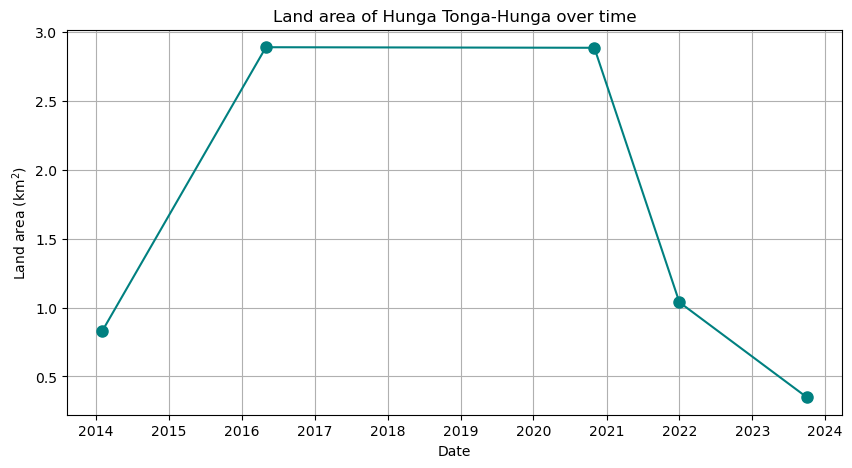

In [66]:
#plot of land area against time 
dates = [get_date(name) for name in area]
areas = [area[name] for name in area]
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(dates, areas, 'o-', color='teal', markersize=8)
ax.set_xlabel('Date')
ax.set_ylabel('Land area (km$^2$)')
plt.grid(True)
ax.set_title('Land area of Hunga Tonga-Hunga over time')
fig.savefig(f'{out_path}/google_land_area_vs_time.png', dpi=150, bbox_inches='tight')
plt.show()

#### note that the january 2022 point on the plot, is probably an overestimation due to some of the clouds being included in the land mask

### 5. Pixel Area for Sentinel Images

In [95]:
#reading pixel size and the bounds from the sentinel images
file =get_sentinel_files(s2_folders[0], 'B04')
with rasterio.open(file) as src:
    resolution = src.res
    bounds =src.bounds
    
print('resolution in degrees:', resolution)
print("bounds in degrees", bounds)

resolution in degrees: (8.988657844990755e-05, 8.412738853502405e-05)
bounds in degrees BoundingBox(left=-175.413508, bottom=-20.557035, right=-175.365958, top=-20.530619)


In [96]:
#defining radius of earth
radius = 6371e3
#finding lattitude at centre of image
centre = (bounds.top + bounds.bottom)/2
#pixel sizein metres 
#radius x angle (in radians)
dx = radius * np.cos(np.radians(centre))*np.radians(resolution[0])
dy = radius * np.radians(resolution[1])
print("the central lattitude :", centre,"degrees")
print("the pixel width is", dx,'m')
print('the pixel height', dy,'m')

the central lattitude : -20.543827 degrees
the pixel width is 9.359294160482648 m
the pixel height 9.35453879695029 m


In [97]:
# calculating pixel area in metre squared 
def sentinel_pixel(file, radius=6371e3):
    with rasterio.open(file) as src:
        resolution = src.res
        bounds = src.bounds
        centre = (bounds.top + bounds.bottom) / 2
        dx = radius * np.cos(np.radians(centre)) * np.radians(resolution[0])
        dy = radius * np.radians(resolution[1])
        return dx* dy
sentenel2_pixels = {}
for file in s2_folders:
    sentenel2_pixels[file] = sentinel_pixel(get_sentinel_files(file, 'B04'))
    print(file,'pixel area:',sentenel2_pixels[file],'m^2' )

S2_2017-07-12 pixel area: 87.55188033630523 m^2
S2_2018-07-12 pixel area: 87.55188033630523 m^2
S2_2019-07-12 pixel area: 87.55188033630523 m^2


#### The Sentinel-2 pixel size is given in degrees, so it was converted to metres using arc length (s = Rθ), with the east-west size scaled by cos(latitude) because lines of longitude converge towards the poles - at the image centre the pixels are 9.35 by 9.36 giving pixel area of 87.55 for all three dates

### 6. NDVI and vegetation mask Sentinel Images

/var/folders/l_/zg2tk5_s42x5rhy4y62g3wh80000gn/T/ipykernel_15489/2167355431.py:10: RuntimeWarning: invalid value encountered in divide
  return (b8-b4) / (b8+b4)


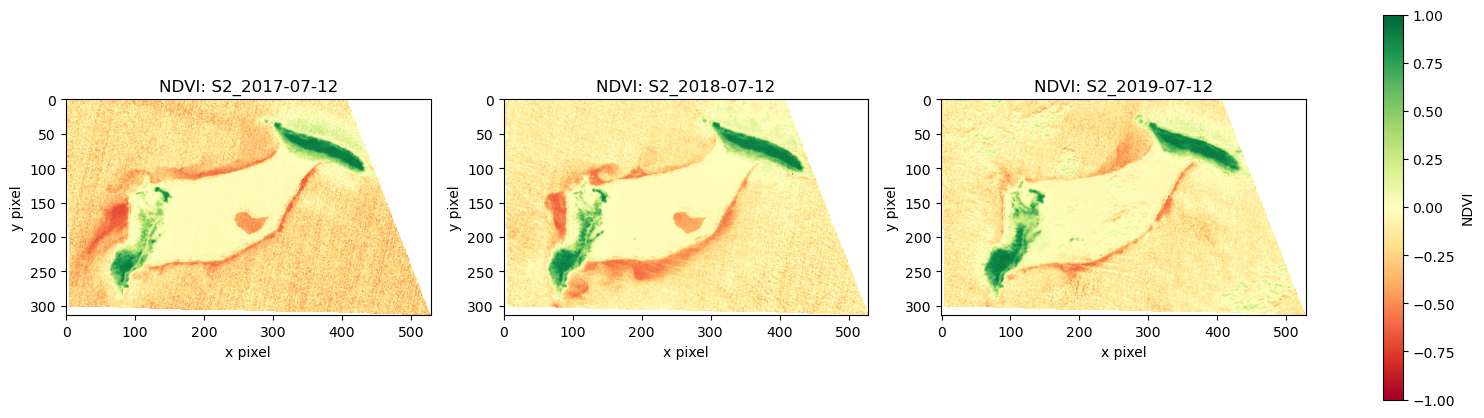

In [99]:
#loading one sentinel band as an array 
def load_band(folder, band):
    with rasterio.open(get_sentinel_files(folder, band)) as src:
        return src.read(1)
    
#NDVI = (b8-b4) / (b8+b4 ) - function to calculate 
def ndvi(folder):
    b4 = load_band(folder, 'B04')
    b8 = load_band(folder, 'B08')
    return (b8-b4) / (b8+b4)

#plottting the NDVI
fig, axes = plt.subplots(1, 3, figsize=(20, 5))
for date, ax in zip(s2_folders, axes):
    im = ax.imshow(ndvi(date), cmap='RdYlGn', vmin=-1, vmax=1)
    ax.set_title(f'NDVI: {date}')
    ax.set_xlabel('x pixel')
    ax.set_ylabel('y pixel')
plt.colorbar(im, ax=axes, label='NDVI')
plt.show()

### NDVI threshold around 0.3 


/var/folders/l_/zg2tk5_s42x5rhy4y62g3wh80000gn/T/ipykernel_15489/2167355431.py:10: RuntimeWarning: invalid value encountered in divide
  return (b8-b4) / (b8+b4)


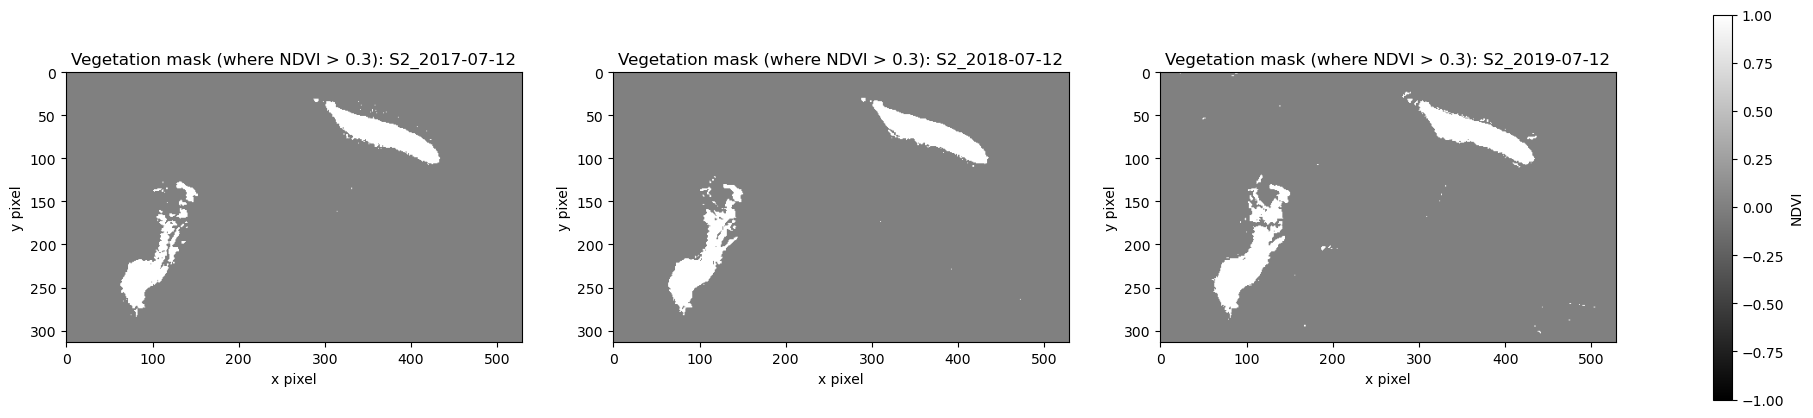

In [104]:
#plotting make to check it is the right areas 
NDVI_threshold = 0.3

def veg_mask(date, threshold =NDVI_threshold):
    return ndvi(date) > threshold

#plotting vegetation mask
fig, axes = plt.subplots(1, 3, figsize=(25, 5))
for date, ax in zip(s2_folders, axes):
    im = ax.imshow(veg_mask(date), cmap='gray', vmin=-1, vmax=1)
    ax.set_title(f'Vegetation mask (where NDVI > {NDVI_threshold}): {date}')
    ax.set_xlabel('x pixel')
    ax.set_ylabel('y pixel')
plt.colorbar(im, ax=axes, label='NDVI')
plt.show()

#### The vegetation threshold was chosen by inspecting the NDVI maps. The vegetated parts of the old islands have NDVI ≈ 0.5–0.9 , the bare ash of the new land is ≈ 0 , and the sea is negative (orange) - a threshold of 0.3 is used to define regions of vegetation - consistent with the commonly used range of 0.2–0.3 for sparse vegetation

In [108]:
#calculating vegetated area - vegetated pixels x pixel area 
veg_area = {
}
for date in s2_folders:
    n_veg = np.sum(veg_mask(date))
    veg_area[date] = n_veg* sentenel2_pixels[date] / 1e6
    print(date, ': vegetation pixels =', n_veg, ', vegetated area =', veg_area[date], 'km^2')

S2_2017-07-12 : vegetation pixels = 6445 , vegetated area = 0.5642718687674873 km^2
S2_2018-07-12 : vegetation pixels = 7232 , vegetated area = 0.6331751985921594 km^2
S2_2019-07-12 : vegetation pixels = 8086 , vegetated area = 0.7079445043993641 km^2


/var/folders/l_/zg2tk5_s42x5rhy4y62g3wh80000gn/T/ipykernel_15489/2167355431.py:10: RuntimeWarning: invalid value encountered in divide
  return (b8-b4) / (b8+b4)


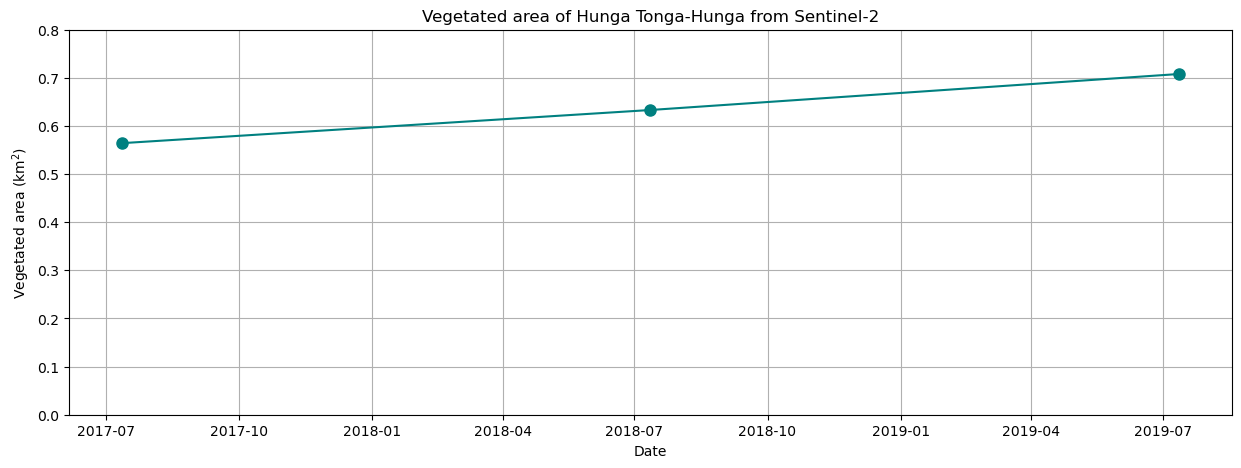

In [111]:
#plot vegetated area agaisnt time 
#plot of vegetated area against time
dates = [dt.datetime.strptime(date[3:], '%Y-%m-%d') for date in veg_area]
areas = [veg_area[date] for date in veg_area]
fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(dates, areas, 'o-', color='teal', markersize=8)
ax.set_xlabel('Date')
ax.set_ylabel('Vegetated area (km$^2$)')
ax.set_title('Vegetated area of Hunga Tonga-Hunga from Sentinel-2')
ax.set_ylim(0,0.8)
plt.grid(True)
fig.savefig(f'{out_path}/sentinel_vegetated_area_vs_time.png', dpi=150, bbox_inches='tight')
plt.show()

### The vegetated area increases from 0.564 km² (2017) to 0.633 km² (2018) and 0.708 km² (2019), a growth of ~25% over two years

### 7. Compare and contrast